# Modélisation Prédictive de la Difficulté des Itinéraires de Ski

* **Projet :** Modélisation prédictive de la difficulté des itinéraires de ski de randonnée
* **Région d'étude :** Canton du Valais, Suisse

Projet académique de Géoinformatique II – UNIL

## Question de recherche
Dans quelle mesure les caractéristiques topographiques des itinéraires de ski de randonnée permettent-elles d'expliquer et de prédire leur niveau de difficulté dans le canton du Valais, et avec quelle incertitude ?

---
## Hypothèses
1. Les caractéristiques topographiques influencent la difficulté des itinéraires : les cotations les plus élevées (AD et D) sont associées à des dénivelés positifs et des longueurs plus importants, ainsi qu'à des pentes moyennes, maximales et au 95e percentile plus fortes.

2. Le modèle de régression logistique permet de reproduire les grandes tendances des cotations : toutefois, l'incertitude des prédictions augmente pour les itinéraires aux profils atypiques, ce qui peut traduire l'influence de facteurs non pris en compte par le modèle, tels que l'exposition ou les difficultés techniques et alpines.
---
## Variables et type de problème

- **Variable à expliquer (\(y\)) :** la cotation de difficulté de l'itinéraire, convertie en une variable numérique catégorielle à quatre classes :
  - **1 = F** : Facile
  - **2 = PD** : Peu Difficile
  - **3 = AD** : Assez Difficile
  - **4 = D** : Difficile

  Il s'agit d'un **problème de classification multiclasse**. Leurs performances sont évaluées à l'aide de l'Accuracy, de la précision, du rappel et du F1-score. Une analyse complémentaire par prédiction conforme permet d'estimer l'incertitude des prédictions en identifiant les classes de difficulté plausibles pour chaque itinéraire.

- **Variables explicatives (\(X\)) :** les caractéristiques morphométriques et topographiques extraites du Modèle Numérique de Terrain (MNT) :
  - Altitude de départ (m)
  - Altitude d'arrivée (m)
  - Longueur de l'itinéraire dans le Valais (km)
  - Dénivelé positif cumulé (m)
  - Pente moyenne (°)
  - Pente maximale (°)
  - 95e percentile de la pente (°)
---

### Données sources

| Donnée / Couche | Source / Fournisseur | Lien de téléchargement / Accès | Licence | Date de téléchargement | Résolution / Format |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **MNT25 (Modèle Numérique de Terrain)** | Office fédéral de topographie (swisstopo) | [swisstopo](https://www.swisstopo.admin.ch) | Open Government Data (OGD) | Octobre 2025 | Raster – 25 m |
| **Limites nationales de la Suisse** | Office fédéral de topographie (swisstopo) | [swissBOUNDARIES3D](https://www.swisstopo.admin.ch) | Open Government Data (OGD) | Octobre 2025 | Vecteur – Polygones |
| **Limites cantonales** | Office fédéral de topographie (swisstopo) | [swissBOUNDARIES3D](https://www.swisstopo.admin.ch) | Open Government Data (OGD) | Octobre 2025 | Vecteur – Polygones |
| **Fond de plan relief léger (WMTS)** | Office fédéral de topographie (swisstopo) | Flux WMTS swisstopo | Données publiques | Octobre 2025 | Raster – Ombrage de relief |
| **Itinéraires de ski / randonnée** | swisstopo / SwissTLM3D ou portails spécialisés | [geocat.ch](https://www.geocat.ch) / Données cantonales du Valais | Données ouvertes / Recherche | Octobre 2025 | Vecteur – Lignes |

---

### Couches géographiques utilisées et créées

| Couche ou raster | Contenu |
| :--- | :--- |
| **input_itineraires_valais** | Couche des itinéraires de ski du canton du Valais, utilisée comme donnée d'entrée pour l'analyse. |
| **input_mnt_valais.tiff** | Modèle numérique de terrain utilisé pour extraire les caractéristiques altitudinales des itinéraires. |
| **input_pente_valais.tif** | Raster de pente utilisé pour caractériser les conditions topographiques des itinéraires. |
| **result_valais** | Polygone du canton du Valais extrait des limites administratives, utilisé pour délimiter la zone d'étude. |


## Instructions pour reproduire le notebook
Pour exécuter et reproduire l'analyse statistique et spatiale de bout en bout :

## Reproduire ce notebook

1. **Environnement :** `environment.yml`, à la racine du dépôt du cours (`Python 3.11`, `geopandas`, `rasterio`, `scikit-learn`, `statsmodels`, `numpy`). La cellule de configuration (§1) affiche les versions effectivement utilisées. Pour figer les versions de votre propre environnement : `conda env export > environment.yml` ou `pip freeze > requirements.txt`.
2. **Données :** téléchargez `andre_denis_projet.zip` depuis le dossier du cours (ou le dépôt) et décompressez-le à côté de ce notebook, pour obtenir le dossier `andre_denis_projet/`. Les chemins sont relatifs (§1) : il n’y a rien d’autre à modifier.
3. **Exécution :** *Kernel - Restart Kernel and Run All Cells* (« Restart & Run All »), environ une minute. La graine aléatoire est fixée (`SEED`, §1) : les résultats sont identiques à chaque exécution. Le notebook ajoute à la géodatabase (`data.gpkg`), ou y remplace, les couches et les rasters décrits ci-dessus.

# 1. Configuration



In [1]:
import sys
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.mask import mask
from rasterio.features import geometry_mask
from rasterio.plot import plotting_extent

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

import sklearn
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)

# ============================================================
# CHEMINS ET PARAMÈTRES
# ============================================================

PROJET = Path("andre_denis_projet")

# GeoPackage directement dans le dossier du projet
GPKG = PROJET / "data.gpkg"

# Rasters
RASTER_MNT = PROJET / "input_mnt_valais.tiff"
RASTER_PENTE = PROJET / "input_pente_valais.tif"
RASTER_FOND = PROJET / "source_fond_carte.tiff"

# Raster MNT source
RASTER_MNT_SOURCE = PROJET / "source_mnt.tiff"

# Graine aléatoire
SEED = 42

# Graine aléatoire : mêmes jeux d'entraînement et de test à chaque exécution
SEED = 42

print(
    f"Exécution du {date.today():%d.%m.%Y} — "
    f"Python {sys.version.split()[0]}, "
    f"numpy {np.__version__}, "
    f"pandas {pd.__version__}, "
    f"geopandas {gpd.__version__}, "
    f"rasterio {rasterio.__version__}, "
    f"scikit-learn {sklearn.__version__}"
)

Exécution du 26.11.2026 — Python 3.13.0, numpy 2.5.5, pandas 2.2.3, geopandas 1.0.1, rasterio 1.5.2, scikit-learn 1.9.1


## 2. Données sources

Les données utilisées pour cette étude sont regroupées dans un GeoPackage (`data.gpkg`) et dans des fichiers raster. Elles constituent les données d'entrée du projet et sont conservées intactes afin de garantir la traçabilité et la reproductibilité des traitements.

### 2.1 Couches vectorielles

Les couches vectorielles sont stockées dans le GeoPackage source `data.gpkg`. Elles contiennent les limites administratives et les itinéraires de ski utilisés pour définir le domaine d'étude et réaliser les analyses spatiales.


In [2]:
# ============================================================
# 2.1 CHARGEMENT DES COUCHES VECTORIELLES SOURCES
# ============================================================

# Lecture des couches sources depuis le GeoPackage

# Limites nationales de la Suisse
pays = gpd.read_file(
    GPKG,
    layer='swisstlmregio_boundaries_lv95__swisstlmregio_landesgebiet'
)

# Limites cantonales
cantons = gpd.read_file(
    GPKG,
    layer='source_swisstlmregio_boundaries_lv95__swisstlmregio_kantonsgebiet'
)

# Itinéraires de ski
itineraires = gpd.read_file(
    GPKG,
    layer='source_ski_routes_2056'
)


# Affichage des informations sur les couches chargées
for nom, gdf in [
    ('Limites nationales', pays),
    ('Limites cantonales', cantons),
    ('Itinéraires de ski', itineraires)
]:
    print(
        f"{nom:<25} {len(gdf):6d} entités   "
        f"SCR : EPSG:{gdf.crs.to_epsg()}   "
        f"Géométrie : {gdf.geom_type.iloc[0]}"
    )

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/pyogrio/raw.py:198: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D Polygon' is converted to 'Polygon Z'
  return ogr_read(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/pyogrio/raw.py:198: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D Polygon' is converted to 'Polygon Z'
  return ogr_read(


Limites nationales            11 entités   SCR : EPSG:2056   Géométrie : Polygon
Limites cantonales            61 entités   SCR : EPSG:2056   Géométrie : Polygon
Itinéraires de ski         10789 entités   SCR : EPSG:2056   Géométrie : MultiLineString


### 2.2 Rasters

Les rasters sources utilisés dans cette étude comprennent le modèle numérique de terrain (MNT), le raster de pente et le fond cartographique issu du service WMTS de swisstopo.

Avant leur utilisation, on vérifie leurs caractéristiques spatiales, notamment le système de coordonnées, la résolution et l'alignement de leur grille. Cette vérification permet de s'assurer de leur compatibilité et de pouvoir, lorsque nécessaire, combiner les rasters pixel par pixel lors des traitements (§4.2).

In [3]:
from pathlib import Path

print("Dossier du projet :", PROJET.resolve())

print("\nRasters trouvés :")
for fichier in PROJET.rglob("*"):
    if fichier.suffix.lower() in [".tif", ".tiff", ".asc"]:
        print(fichier)

Dossier du projet : /Users/andredenis/Library/CloudStorage/OneDrive-OneDrive-UniversitédeLausanne(2)/3eme/Geoinfo2/andre_denis_projet

Rasters trouvés :
andre_denis_projet/source_mnt.tiff
andre_denis_projet/source_fond_carte.tiff
andre_denis_projet/input_pente_valais.tiff.tif
andre_denis_projet/input_pente_valais_alignee.tif
andre_denis_projet/input_pente_valais.tif
andre_denis_projet/input_mnt_valais.tiff


In [4]:
# ============================================================
# 2.2.1 VÉRIFICATION DES RASTERS SOURCES
# ============================================================

# Rasters utilisés dans le projet
RASTERS = {
    'altitude': 'input_mnt_valais.tiff',
    'pente': 'input_pente_valais.tif',
}

# Fond cartographique extrait du service WMTS swisstopo
FOND_CARTE = 'source_fond_carte.tiff'


# ============================================================
# 2.2.2 EXTRACTION DES MÉTADONNÉES
# ============================================================

metadonnees = []

for variable, fichier in list(RASTERS.items()) + [
    ('fond_cartographique', FOND_CARTE)
]:

    with rasterio.open(PROJET / fichier) as src:

        metadonnees.append({
            'fichier': fichier,
            'variable': variable,
            'SCR': f'EPSG:{src.crs.to_epsg()}',
            'lignes × colonnes': f'{src.height} × {src.width}',
            'résolution (m)': src.res,
            'coin supérieur gauche': (
                f'({src.transform.c:.0f}, '
                f'{src.transform.f:.0f})'
            ),
            'type': src.dtypes[0],
            'NoData': src.nodata,
        })


# Affichage du tableau récapitulatif
pd.DataFrame(metadonnees).set_index('fichier')

,variable,SCR,lignes × colonnes,résolution (m),coin supérieur gauche,type,NoData
fichier,,,,,,,
input_mnt_valais.tiff,altitude,EPSG:2056,3556 × 5248,"(25.00005648787246, 25.00020915787376)","(2548562, 1167437)",float32,-9999.0
input_pente_valais.tif,pente,EPSG:2056,3556 × 5248,"(25.00005648787246, 25.00020915787376)","(2548562, 1167437)",float32,-9999.0
source_fond_carte.tiff,fond_cartographique,EPSG:2056,13312 × 20480,"(25.0, 25.0)","(2419996, 1350004)",uint8,NaN


## 3. Analyse exploratoire des données brutes

Avant de procéder aux traitements et à la modélisation, une analyse exploratoire des données est réalisée afin de mieux comprendre les caractéristiques spatiales et topographiques des itinéraires de ski de randonnée.

Cette étape permet de visualiser la répartition géographique des itinéraires sur le territoire valaisan, d'identifier leur distribution spatiale et de vérifier leur correspondance avec les données topographiques utilisées dans l'étude.

### 3.1 Carte de l'inventaire des itinéraires

Une première représentation cartographique permet de visualiser l'ensemble des itinéraires de ski de randonnée recensés dans le canton du Valais. Cette carte constitue un aperçu général du jeu de données initial et permet de situer les itinéraires dans leur contexte géographique.

Le fond cartographique swisstopo est utilisé pour faciliter la lecture et la localisation des itinéraires.

### 3.2 Variables explicatives

L'analyse repose sur sept variables explicatives décrivant les caractéristiques topographiques des itinéraires de ski de randonnée. Ces variables sont extraites à partir du modèle numérique de terrain (MNT), du raster de pente et de la géométrie des itinéraires.

Elles comprennent l'altitude au départ et à l'arrivée, la longueur de l'itinéraire, le dénivelé positif, ainsi que plusieurs indicateurs de pente : la pente moyenne, la pente maximale et le 95e percentile des valeurs de pente.

La variable à expliquer correspond à la cotation officielle de difficulté des itinéraires. Elle est regroupée en quatre catégories : F, PD, AD et D.

Les deux rasters topographiques utilisés dans cette étude sont le modèle numérique de terrain (MNT) et le raster de pente. Le MNT fournit les informations d'altitude, tandis que le raster de pente permet de caractériser l'inclinaison du terrain.

Ces deux sources constituent la base de l'extraction des variables topographiques utilisées pour caractériser les itinéraires de ski de randonnée.

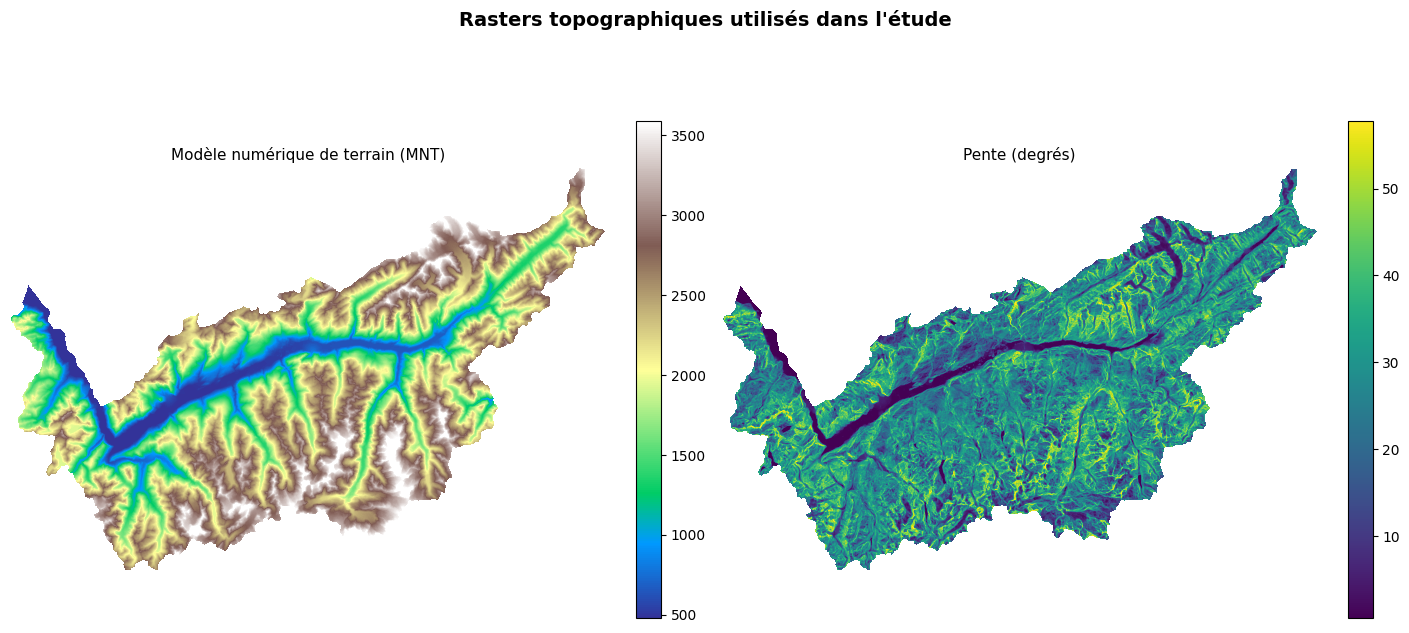

In [5]:
# ============================================================
# 3.2 VISUALISATION DES RASTERS UTILISES
# ============================================================

RASTERS = {
    "Modèle numérique de terrain (MNT)": "input_mnt_valais.tiff",
    "Pente (degrés)": "input_pente_valais.tif"
}

fig, axes = plt.subplots(1, 2, figsize=(14, 7), layout="constrained")

for ax, (nom, fichier) in zip(axes.ravel(), RASTERS.items()):

    with rasterio.open(PROJET / fichier) as src:
        valeurs = src.read(1, masked=True).astype("float32").filled(np.nan)

    # Étirement de la palette entre les centiles 2 et 98
    vmin = np.nanpercentile(valeurs, 2)
    vmax = np.nanpercentile(valeurs, 98)

    im = ax.imshow(
        valeurs,
        cmap="terrain" if "MNT" in nom else "viridis",
        vmin=vmin,
        vmax=vmax
    )

    plt.colorbar(im, ax=ax, shrink=0.75)
    ax.set_title(nom, fontsize=11)
    ax.set_axis_off()

fig.suptitle(
    "Rasters topographiques utilisés dans l'étude",
    fontsize=14,
    fontweight="bold"
)

plt.show()


## 4. Chaîne de prétraitements : des données sources au tableau d’analyse

Avant de procéder à l'analyse des itinéraires et à la modélisation, plusieurs traitements géomatiques sont réalisés afin de préparer et d'harmoniser les données sources. Cette chaîne de prétraitements permet de délimiter le domaine d'étude, d'extraire les itinéraires concernés et de produire les données topographiques nécessaires à l'analyse.

Les traitements sont effectués à l'aide de Python, principalement avec les bibliothèques GeoPandas, Rasterio et NumPy.

### 4.1 Extraction du canton du Valais

La première opération consiste à extraire le canton du Valais à partir de la couche des limites cantonales contenue dans le GeoPackage source.

Le canton est identifié automatiquement à partir de ses attributs, en recherchant les valeurs « Valais » ou « Wallis ». La géométrie correspondante est ensuite exportée dans un nouveau GeoPackage sous le nom de couche `result_valais`.

Cette opération permet de définir le périmètre géographique de l'étude et de disposer d'une couche de référence pour les traitements spatiaux suivants.


### 4.2 Sélection des itinéraires de ski en Valais

La deuxième opération consiste à sélectionner les itinéraires de ski de randonnée qui intersectent le canton du Valais.

La couche des itinéraires est d'abord reprojetée dans le même système de coordonnées que celui du canton, si nécessaire. Une intersection spatiale est ensuite effectuée entre les géométries des itinéraires et celle du Valais.

Les itinéraires qui intersectent le canton sont conservés et exportés dans le GeoPackage de résultats sous le nom `input_itineraires_valais`. Les géométries originales sont conservées dans leur intégralité, même lorsqu'un itinéraire dépasse les limites cantonales.

Cette sélection permet de constituer le jeu de données des itinéraires concernés par le domaine d'étude.



### 4.3 Découpage du modèle numérique de terrain

Le modèle numérique de terrain (MNT) source couvre une zone plus vaste que le domaine d'étude. Il est donc découpé à l'aide de la géométrie du canton du Valais.

La géométrie du canton est d'abord reprojetée dans le système de coordonnées du raster. Le découpage est ensuite effectué avec Rasterio, en conservant uniquement les pixels situés à l'intérieur du canton. Le raster obtenu est enregistré au format GeoTIFF sous le nom `mnt_valais.tif`.

Cette opération réduit l'emprise des données et permet de limiter les traitements ultérieurs à la zone d'étude.


**Le code Python contient un paramètre True ou False permettant de choisir si les résultats du géotraitement doivent être enregistrés ou non. Il suffit de modifier cette valeur selon le besoin.**

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/pyogrio/raw.py:198: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D Polygon' is converted to 'Polygon Z'
  return ogr_read(


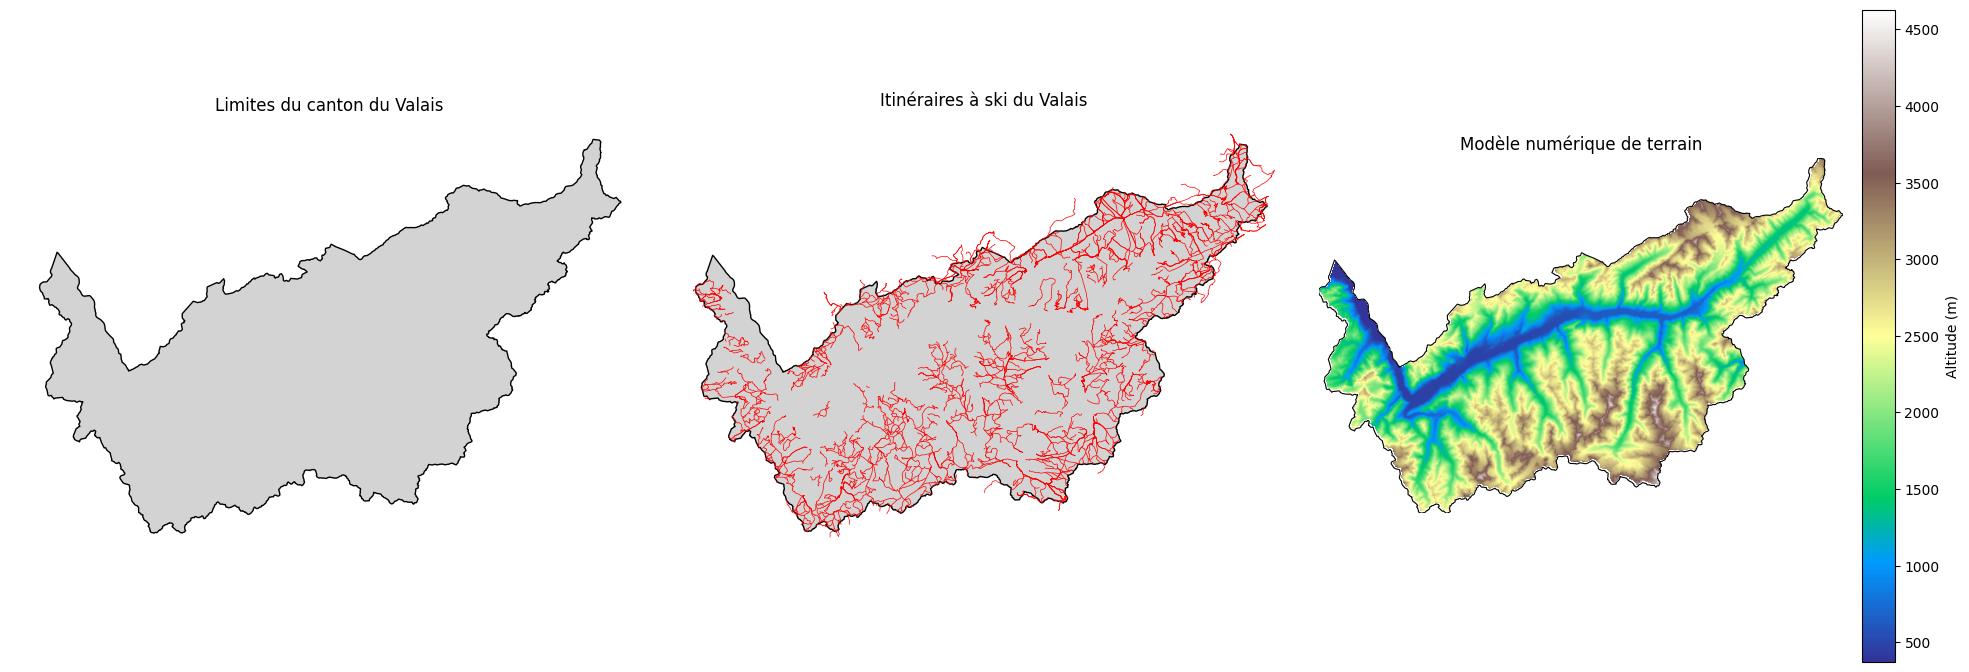

In [6]:

from pathlib import Path

import geopandas as gpd
import rasterio
import numpy as np
import matplotlib.pyplot as plt

from rasterio.mask import mask
from rasterio.transform import array_bounds


# ============================================================
# 1. PARAMÈTRES
# ============================================================

# True  = enregistre les résultats
# False = affiche les résultats sans les enregistrer

ENREGISTRER = False

PROJET = Path("andre_denis_projet")

GPKG = PROJET / "data.gpkg"
MNT_SOURCE = PROJET / "source_mnt.tiff"

MNT_VALAIS = PROJET / "input_mnt_valais.tiff"

COUCHE_CANTONS = (
    "source_swisstlmregio_boundaries_lv95__"
    "swisstlmregio_kantonsgebiet"
)

COUCHE_ITINERAIRES = "source_ski_routes_2056"

NODATA = -9999


# ============================================================
# 2. LECTURE DES DONNÉES
# ============================================================

cantons = gpd.read_file(
    GPKG,
    layer=COUCHE_CANTONS
)

itineraires = gpd.read_file(
    GPKG,
    layer=COUCHE_ITINERAIRES
)

# Identifier le canton du Valais

result_valais = None

for colonne in cantons.columns:

    valeurs = cantons[colonne].astype(str).str.lower()

    selection = cantons[
        valeurs.isin(["valais", "wallis"])
    ]

    if not selection.empty:
        result_valais = selection.copy()
        break

if result_valais is None:
    raise ValueError(
        "Impossible de trouver le canton du Valais."
    )




# ============================================================
# 3. SÉLECTION DES ITINÉRAIRES DU VALAIS
# ============================================================

# Mettre les itinéraires dans le même système de coordonnées
# que le canton.

if itineraires.crs != result_valais.crs:

    itineraires = itineraires.to_crs(
        result_valais.crs
    )

# Géométrie du canton

valais_union = result_valais.geometry.union_all()

# Sélectionner les itinéraires qui intersectent le Valais.
# Les géométries originales ne sont pas découpées.

input_itineraires_valais = itineraires[
    itineraires.geometry.intersects(valais_union)
].copy()




# ============================================================
# 4. DÉCOUPAGE DU MNT SUR LE VALAIS
# ============================================================

with rasterio.open(MNT_SOURCE) as src:

    # Transformer le canton dans le CRS du raster

    valais_raster = result_valais.to_crs(src.crs)

    geometries = [
        geom.__geo_interface__
        for geom in valais_raster.geometry
        if geom is not None
    ]

    # Découper le MNT selon les limites du Valais

    image, transform = mask(
        src,
        geometries,
        crop=True,
        nodata=NODATA,
        filled=True
    )

    # Travailler sur la première bande du raster

    mnt = image[0].astype("float32")

    # Informations du raster

    profil = src.profile.copy()

    profil.update(
        height=mnt.shape[0],
        width=mnt.shape[1],
        transform=transform,
        nodata=NODATA,
        dtype="float32",
        count=1
    )




# ============================================================
# 5. ENREGISTREMENT DES RÉSULTATS
# ============================================================

if ENREGISTRER:

    print("Enregistrement des résultats...")

    import pyogrio

    # Vérifier les couches déjà présentes dans le GeoPackage

    couches_existantes = [
        couche[0]
        for couche in pyogrio.list_layers(GPKG)
    ]

    nouvelles_couches = [
        "result_valais",
        "input_itineraires_valais"
    ]

    deja_presentes = [
        couche
        for couche in nouvelles_couches
        if couche in couches_existantes
    ]

    if deja_presentes:
        raise ValueError(
            "Les couches suivantes existent déjà dans data.gpkg : "
            + ", ".join(deja_presentes)
            + ". Supprime uniquement ces couches dans QGIS "
            "avant de relancer le script."
        )

    # Enregistrer le canton du Valais

    result_valais.to_file(
        GPKG,
        layer="result_valais",
        driver="GPKG",
        engine="pyogrio",
        mode="a"
    )

    # Enregistrer les itinéraires du Valais

    input_itineraires_valais.to_file(
        GPKG,
        layer="input_itineraires_valais",
        driver="GPKG",
        engine="pyogrio",
        mode="a"
    )

    # Enregistrer le MNT découpé

    with rasterio.open(
        MNT_VALAIS,
        "w",
        **profil
    ) as dst:

        dst.write(mnt, 1)

    print("Enregistrement terminé.")



# ============================================================
# 6. AFFICHAGE DES RÉSULTATS
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(20, 9)
)


# ------------------------------------------------------------
# 6.1 Limites du canton du Valais
# ------------------------------------------------------------

result_valais.plot(
    ax=axes[0],
    facecolor="lightgrey",
    edgecolor="black",
    linewidth=1
)

axes[0].set_title(
    "Limites du canton du Valais"
)

axes[0].set_axis_off()


# ------------------------------------------------------------
# 6.2 Itinéraires à ski sur le fond du Valais
# ------------------------------------------------------------

result_valais.plot(
    ax=axes[1],
    facecolor="lightgrey",
    edgecolor="black",
    linewidth=1
)

input_itineraires_valais.plot(
    ax=axes[1],
    color="red",
    linewidth=0.5
)

axes[1].set_title(
    "Itinéraires à ski du Valais"
)

axes[1].set_axis_off()


# ------------------------------------------------------------
# 6.3 Modèle numérique de terrain avec limite du Valais
# ------------------------------------------------------------

hauteur, largeur = mnt.shape

bounds = array_bounds(
    hauteur,
    largeur,
    transform
)

extent = [
    bounds[0],
    bounds[2],
    bounds[1],
    bounds[3]
]

mnt_affiche = np.ma.masked_where(
    mnt == NODATA,
    mnt
)

image = axes[2].imshow(
    mnt_affiche,
    extent=extent,
    origin="upper",
    cmap="terrain"
)

# Ajouter les limites du Valais

result_valais.boundary.plot(
    ax=axes[2],
    color="black",
    linewidth=0.8
)

# Ajouter l'échelle d'altitude

cbar = fig.colorbar(
    image,
    ax=axes[2],
    shrink=0.75,
    pad=0.03
)

cbar.set_label(
    "Altitude (m)"
)

axes[2].set_title(
    "Modèle numérique de terrain"
)

axes[2].set_axis_off()


# ------------------------------------------------------------
# AFFICHAGE FINAL
# ------------------------------------------------------------

plt.tight_layout()
plt.show()




### 4.4 Calcul du raster de pente

À partir du modèle numérique de terrain (MNT) découpé sur le domaine d'étude, un raster de pente est généré à l'aide de l'outil « Pente » de QGIS (GDAL). Cet outil calcule l'inclinaison du terrain à partir des variations d'altitude entre les cellules voisines du raster.

La pente est exprimée en degrés et le raster obtenu est enregistré au format GeoTIFF sous le nom input_pente_valais.tif.

Cette couche fournit une information topographique complémentaire au MNT. Elle est ensuite utilisée pour caractériser les conditions de pente le long des itinéraires de ski de randonnée.

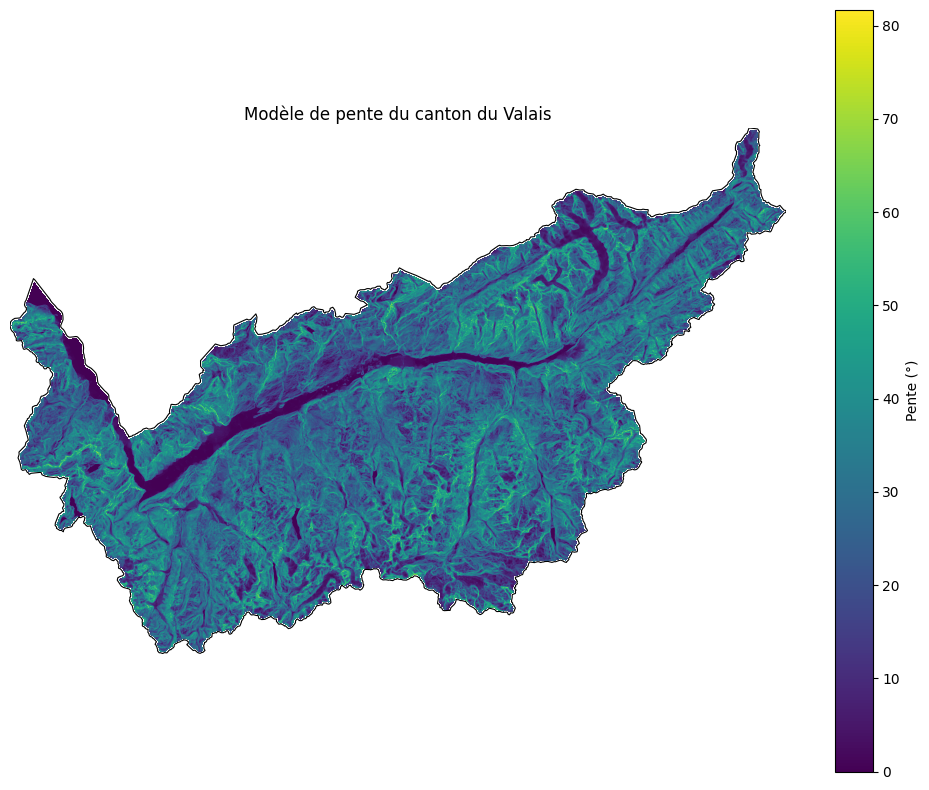

In [7]:

with rasterio.open(PROJET / "input_pente_valais.tif") as src:

    pente = src.read(1).astype("float32")

    pente_nodata = src.nodata

    hauteur, largeur = pente.shape

    bounds = array_bounds(
        hauteur,
        largeur,
        src.transform
    )

    extent = [
        bounds[0],
        bounds[2],
        bounds[1],
        bounds[3]
    ]

pente_affiche = np.ma.masked_where(
    pente == pente_nodata,
    pente
)

fig, ax = plt.subplots(figsize=(10, 8))

# Afficher le raster de pente

image = ax.imshow(
    pente_affiche,
    extent=extent,
    origin="upper",
    cmap="viridis"
)

# Ajouter les limites du canton du Valais

result_valais.to_crs(
    result_valais.crs
).boundary.plot(
    ax=ax,
    color="black",
    linewidth=0.8
)

# Ajouter l'échelle des pentes

plt.colorbar(
    image,
    ax=ax,
    label="Pente (°)"
)

ax.set_title("Modèle de pente du canton du Valais")
ax.set_axis_off()

plt.tight_layout()
plt.show()


### 4.5 Contrôle du tableau d’analyse

Avant de procéder à la modélisation, le tableau d’analyse est examiné afin d'identifier les relations entre les variables topographiques et la cotation des itinéraires à ski. Les premières observations montrent que la pente joue un rôle important dans la distinction des niveaux de difficulté. L'altitude d'arrivée ainsi que le dénivelé positif semblent également présenter une influence sur la cotation des itinéraires.

Ces observations confirment l'intérêt de conserver ces variables comme facteurs explicatifs dans le modèle de régression.

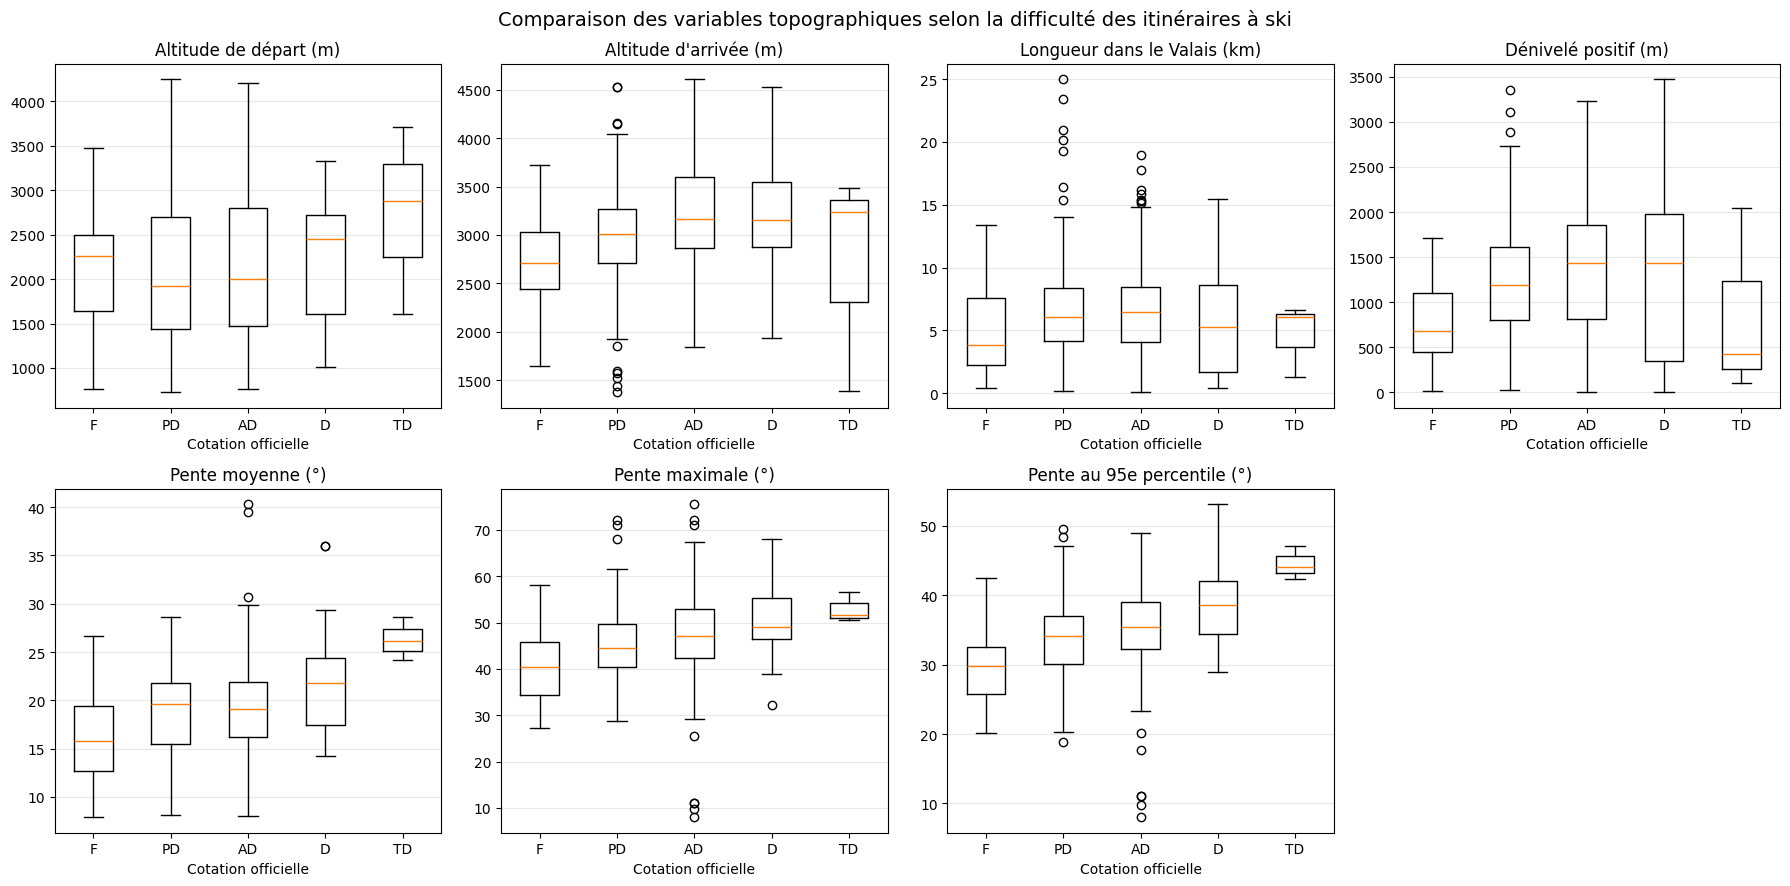

In [8]:



import math
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

from rasterio.warp import reproject, Resampling
from shapely.geometry import (
    LineString,
    MultiLineString,
    GeometryCollection
)


# ============================================================
# 1. PARAMÈTRES
# ============================================================

PROJET = Path("andre_denis_projet")

GPKG = PROJET / "data.gpkg"

MNT_PATH = PROJET / "input_mnt_valais.tiff"
PENTE_PATH = PROJET / "input_pente_valais.tif"

PENTE_ALIGNEE_PATH = PROJET / "input_pente_valais_alignee.tif"

LAYER_ITINERAIRES = "input_itineraires_valais"
LAYER_VALAIS = "result_valais"

LAYER_SORTIE = "analyse_itineraires_cotes"

ORDRE_CLASSES = ["F", "PD", "AD", "D", "TD"]

CORRESPONDANCE_COTATION = {
    "F": 1,
    "PD": 2,
    "AD": 3,
    "D": 4,
    "TD": 5
}


# ============================================================
# 2. CHARGEMENT DES DONNÉES
# ============================================================

itineraires = gpd.read_file(
    GPKG,
    layer=LAYER_ITINERAIRES
)

valais = gpd.read_file(
    GPKG,
    layer=LAYER_VALAIS
)


# ============================================================
# 3. NETTOYAGE ET FILTRAGE DES COTATIONS
# ============================================================

itineraires["cotation_nettoyee"] = (
    itineraires["difficulty_fr"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.replace("−", "-", regex=False)
    .str.replace(r"[+-]", "", regex=True)
    .str.strip()
)

itineraires["difficulte"] = (
    itineraires["cotation_nettoyee"]
    .map(CORRESPONDANCE_COTATION)
)

itineraires = itineraires.dropna(
    subset=["difficulte"]
).copy()

itineraires["difficulte"] = (
    itineraires["difficulte"].astype(int)
)

itineraires["cotation"] = pd.Categorical(
    itineraires["cotation_nettoyee"],
    categories=ORDRE_CLASSES,
    ordered=True
)


# ============================================================
# 4. PRÉPARATION DES GÉOMÉTRIES
# ============================================================

with rasterio.open(MNT_PATH) as src_mnt:

    crs_mnt = src_mnt.crs

    resolution = min(
        abs(src_mnt.transform.a),
        abs(src_mnt.transform.e)
    )

itineraires = itineraires.to_crs(crs_mnt)
valais = valais.to_crs(crs_mnt)

geom_valais = valais.geometry.union_all()

geometries_analyse = []

for geom in itineraires.geometry:

    if geom is None or geom.is_empty:
        geometries_analyse.append(None)
        continue

    intersection = geom.intersection(geom_valais)

    if intersection.is_empty:
        geometries_analyse.append(None)
    else:
        geometries_analyse.append(intersection)

itineraires["geometry_analyse"] = geometries_analyse

itineraires = itineraires[
    itineraires["geometry_analyse"].notna()
].copy()


# ============================================================
# 5. ALIGNEMENT DU RASTER DE PENTE SUR LE MNT
# ============================================================

with rasterio.open(MNT_PATH) as src_mnt:

    profil_mnt = src_mnt.profile.copy()

    with rasterio.open(PENTE_PATH) as src_pente:

        if src_mnt.crs is None or src_pente.crs is None:
            raise ValueError(
                "Le MNT et le raster de pente doivent avoir un CRS."
            )

        pente_alignee = np.full(
            (src_mnt.height, src_mnt.width),
            -9999,
            dtype="float32"
        )

        reproject(
            source=rasterio.band(src_pente, 1),
            destination=pente_alignee,
            src_transform=src_pente.transform,
            src_crs=src_pente.crs,
            src_nodata=src_pente.nodata,
            dst_transform=src_mnt.transform,
            dst_crs=src_mnt.crs,
            dst_nodata=-9999,
            resampling=Resampling.bilinear
        )

        profil_mnt.update(
            dtype="float32",
            nodata=-9999,
            count=1,
            compress="lzw"
        )

        with rasterio.open(
            PENTE_ALIGNEE_PATH,
            "w",
            **profil_mnt
        ) as dst:

            dst.write(pente_alignee, 1)


# ============================================================
# 6. FONCTIONS D'EXTRACTION DES VARIABLES
# ============================================================

def extraire_segments(geom):

    if geom is None or geom.is_empty:
        return []

    if isinstance(geom, LineString):
        return [geom]

    if isinstance(geom, MultiLineString):
        return list(geom.geoms)

    if isinstance(geom, GeometryCollection):

        segments = []

        for element in geom.geoms:
            segments.extend(extraire_segments(element))

        return segments

    return []


def valeurs_raster(src, points):

    if len(points) == 0:
        return np.array([])

    coordonnees = [
        (point.x, point.y)
        for point in points
    ]

    valeurs = list(
        src.sample(coordonnees, masked=True)
    )

    resultat = []

    for valeur in valeurs:

        v = valeur[0]

        if np.ma.is_masked(v):
            resultat.append(np.nan)
            continue

        v = float(v)

        if not np.isfinite(v):
            resultat.append(np.nan)

        elif src.nodata is not None and np.isclose(v, src.nodata):
            resultat.append(np.nan)

        else:
            resultat.append(v)

    return np.array(resultat, dtype=float)


def calculer_variables(geom, src_mnt, src_pente):

    segments = extraire_segments(geom)

    if len(segments) == 0:
        return None

    toutes_altitudes = []
    toutes_pentes = []

    denivele_positif = 0

    for segment in segments:

        longueur = segment.length

        if longueur <= 0:
            continue

        nombre_points = max(
            2,
            int(math.ceil(longueur / resolution)) + 1
        )

        distances = np.linspace(
            0,
            longueur,
            nombre_points
        )

        points = [
            segment.interpolate(distance)
            for distance in distances
        ]

        altitudes = valeurs_raster(
            src_mnt,
            points
        )

        pentes = valeurs_raster(
            src_pente,
            points
        )

        altitudes_valides = altitudes[
            np.isfinite(altitudes)
        ]

        pentes_valides = pentes[
            np.isfinite(pentes)
        ]

        if len(altitudes_valides) > 0:

            toutes_altitudes.extend(
                altitudes_valides.tolist()
            )

            denivele_positif += np.maximum(
                np.diff(altitudes_valides),
                0
            ).sum()

        if len(pentes_valides) > 0:

            toutes_pentes.extend(
                pentes_valides.tolist()
            )

    if len(toutes_altitudes) < 2:
        return None

    if len(toutes_pentes) == 0:
        return None

    altitudes = np.array(
        toutes_altitudes,
        dtype=float
    )

    pentes = np.array(
        toutes_pentes,
        dtype=float
    )

    return {
        "altitude_depart": altitudes[0],
        "altitude_arrivee": altitudes[-1],
        "longueur_valais_km": geom.length / 1000,
        "denivele_positif": denivele_positif,
        "pente_moyenne": np.mean(pentes),
        "pente_max": np.max(pentes),
        "pente_p95": np.percentile(pentes, 95)
    }


# ============================================================
# 7. CALCUL DES VARIABLES TOPOGRAPHIQUES
# ============================================================

resultats = []

with rasterio.open(MNT_PATH) as src_mnt, \
     rasterio.open(PENTE_ALIGNEE_PATH) as src_pente:

    for index, ligne in itineraires.iterrows():

        geom = ligne["geometry_analyse"]

        variables = calculer_variables(
            geom,
            src_mnt,
            src_pente
        )

        if variables is None:
            continue

        resultats.append({
            "index_original": index,
            **variables
        })


# ============================================================
# 8. CRÉATION DU TABLEAU FINAL
# ============================================================

tableau = pd.DataFrame(resultats)

if tableau.empty:
    raise ValueError(
        "Aucun itinéraire n'a pu être analysé. "
        "Vérifie les rasters et les géométries."
    )

itineraires_resultats = itineraires.loc[
    tableau["index_original"].tolist()
].copy()

tableau.index = itineraires_resultats.index

for colonne in tableau.columns:

    if colonne != "index_original":
        itineraires_resultats[colonne] = tableau[colonne]

itineraires_resultats = itineraires_resultats.drop(
    columns=["geometry_analyse", "index_original"],
    errors="ignore"
)


# ============================================================
# 9. ENREGISTREMENT DANS LE GEOPACKAGE
# ============================================================

itineraires_resultats.to_file(
    GPKG,
    layer=LAYER_SORTIE,
    driver="GPKG"
)


# ============================================================
# 10. BOXPLOTS DES VARIABLES TOPOGRAPHIQUES
# ============================================================

variables_a_tracer = [
    ("altitude_depart", "Altitude de départ (m)"),
    ("altitude_arrivee", "Altitude d'arrivée (m)"),
    ("longueur_valais_km", "Longueur dans le Valais (km)"),
    ("denivele_positif", "Dénivelé positif (m)"),
    ("pente_moyenne", "Pente moyenne (°)"),
    ("pente_max", "Pente maximale (°)"),
    ("pente_p95", "Pente au 95e percentile (°)")
]

fig, axes = plt.subplots(
    2,
    4,
    figsize=(18, 9)
)

axes = axes.flatten()

for i, (variable, titre) in enumerate(variables_a_tracer):

    donnees = []
    labels = []

    for classe in ORDRE_CLASSES:

        valeurs = itineraires_resultats.loc[
            itineraires_resultats["cotation"] == classe,
            variable
        ].dropna()

        if len(valeurs) > 0:
            donnees.append(valeurs)
            labels.append(classe)

    if len(donnees) > 0:

        axes[i].boxplot(
            donnees,
            tick_labels=labels
        )

    axes[i].set_title(titre)
    axes[i].set_xlabel("Cotation officielle")
    axes[i].grid(axis="y", alpha=0.3)

fig.delaxes(axes[7])

fig.suptitle(
    "Comparaison des variables topographiques "
    "selon la difficulté des itinéraires à ski",
    fontsize=14
)

plt.tight_layout()
plt.show()





## 5. Modélisation : prédiction de la difficulté des itinéraires

L'objectif de cette étape est d'étudier dans quelle mesure les caractéristiques topographiques permettent d'expliquer et de prédire la difficulté des itinéraires de ski de randonnée dans le canton du Valais.

La variable à expliquer correspond à la cotation officielle de difficulté des itinéraires. Les variables explicatives sont les caractéristiques topographiques extraites lors des étapes précédentes : l'altitude, la longueur, le dénivelé positif ainsi que les différentes mesures de pente.

La cotation de difficulté étant constituée de catégories, le problème est abordé comme une **classification**. Le modèle cherche à attribuer à chaque itinéraire une catégorie de difficulté à partir de ses caractéristiques topographiques.

**Démarche.**

1. **Préparer les données** : sélectionner les variables explicatives et la variable cible, puis vérifier les données utilisées pour la modélisation.
2. **Séparer les données** : constituer un jeu d'entraînement et un jeu de test afin de pouvoir évaluer le modèle sur des observations qui n'ont pas servi à son ajustement.
3. **Entraîner les modèles** : ajuster les modèles de classification retenus à partir du jeu d'entraînement.
4. **Évaluer les prédictions** : comparer les résultats obtenus sur le jeu de test à l'aide de métriques adaptées à la classification, notamment l'exactitude, la précision, le rappel, le score F1 et la matrice de confusion.
5. **Interpréter les résultats** : examiner l'influence et l'importance des variables topographiques dans la prédiction de la difficulté des itinéraires.

Cette démarche permet d'évaluer la capacité des caractéristiques topographiques à reproduire les cotations officielles et d'identifier les variables qui contribuent le plus à la difficulté des itinéraires.



### 5.1 Séparation en jeux d'entraînement et de test

Les itinéraires de ski de randonnée sont répartis en deux ensembles afin de pouvoir entraîner et évaluer les modèles de classification.

La séparation est effectuée de manière aléatoire, avec une proportion de 80 % des itinéraires attribués au jeu d'entraînement et de 20 % au jeu de test.

Le jeu d'entraînement est utilisé pour ajuster les modèles à partir des caractéristiques topographiques des itinéraires. Le jeu de test est conservé séparément afin d'évaluer les performances des modèles sur des itinéraires qui n'ont pas été utilisés lors de leur entraînement.

Une graine aléatoire fixe (`random_state = 42`) est utilisée afin de garantir la reproductibilité de la séparation.




La modélisation repose uniquement sur les itinéraires pour lesquels une cotation de difficulté est renseignée dans la couche d'origine. Les itinéraires sans cotation sont écartés de cette étape, car ils ne disposent pas d'une valeur de référence permettant d'entraîner le modèle.

Les cotations sont ensuite transformées en valeurs numériques afin de pouvoir être utilisées comme variable cible :
- F : 1
- PD : 2
- AD : 3
- D : 4

Les signes « + » et « - » sont supprimés lors du nettoyage des cotations. Les cotations non reconnues sont également écartées.

Pour chaque itinéraire, les variables topographiques sont extraites à partir du modèle numérique de terrain (MNT). Les itinéraires pour lesquels certaines de ces variables ne peuvent pas être calculées sont exclus de la modélisation.

Les données restantes sont ensuite réparties aléatoirement en deux ensembles :
- **Jeu d'entraînement (80 %)** : utilisé pour ajuster le modèle de régression à partir des variables topographiques et des cotations connues.
- **Jeu de test (20 %)** : utilisé pour évaluer les performances du modèle sur des itinéraires qui n'ont pas participé à son entraînement.

La séparation est réalisée avec une graine aléatoire fixe (`random_state = 42`) afin de garantir la reproductibilité des résultats.

Les itinéraires sans cotation pourront être utilisés ultérieurement pour appliquer le modèle et obtenir une estimation de leur difficulté.


In [9]:
# ============================================================
# BILAN DES ITINÉRAIRES ET DES COTATIONS
# ============================================================

from pathlib import Path
import geopandas as gpd

# Chemins
PROJET = Path("andre_denis_projet")
GPKG = PROJET / "data.gpkg"

# Lecture de la couche des itinéraires
itineraires = gpd.read_file(
    GPKG,
    layer="input_itineraires_valais"
)

# Vérifier la présence de la colonne des cotations
if "difficulty_fr" not in itineraires.columns:
    raise ValueError("La colonne 'difficulty_fr' est absente de la couche.")

# Identifier les cotations renseignées
cotations_renseignees = (
    itineraires["difficulty_fr"].notna()
    & itineraires["difficulty_fr"].astype(str).str.strip().ne("")
)

# Comptage
nombre_total = len(itineraires)
nombre_avec_cotation = int(cotations_renseignees.sum())
nombre_sans_cotation = nombre_total - nombre_avec_cotation

# Affichage
print("\nBILAN DES ITINÉRAIRES")
print("----------------------------")
print(f"Nombre total d'itinéraires : {nombre_total}")
print(f"Itinéraires avec cotation : {nombre_avec_cotation}")
print(f"Itinéraires sans cotation : {nombre_sans_cotation}")

if nombre_total > 0:
    print(
        f"Pourcentage avec cotation : "
        f"{nombre_avec_cotation / nombre_total * 100:.1f} %"
    )


BILAN DES ITINÉRAIRES
----------------------------
Nombre total d'itinéraires : 2461
Itinéraires avec cotation : 580
Itinéraires sans cotation : 1881
Pourcentage avec cotation : 23.6 %



### 5.2 Entraînement du modèle de régression

Un modèle de régression logistique est utilisé afin d'estimer la difficulté des itinéraires à partir de leurs caractéristiques topographiques.

L'entraînement est réalisé avec les 80 % d'itinéraires précédemment sélectionnés. Les sept variables explicatives sont utilisées simultanément :
- Altitude de départ ;
- Altitude d'arrivée ;
- Longueur de l'itinéraire ;
- Dénivelé positif ;
- Pente moyenne ;
- Pente maximale ;
- Pente au 95e percentile.


Le modèle ajuste les coefficients associés à chacune des variables explicatives afin de minimiser les écarts entre les cotations observées et les valeurs estimées sur le jeu d'entraînement.

Une fois entraîné, le modèle pourra être utilisé pour prédire la difficulté des itinéraires du jeu de test, puis celle des itinéraires ne disposant pas de cotation.



CHARGEMENT DES DONNEES
Nombre initial d'itinéraires : 2461


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/pyogrio/raw.py:198: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D Polygon' is converted to 'Polygon Z'
  return ogr_read(


Résolution du MNT : 25.00005648787246 m

Calcul des variables topographiques...
100 / 2461 itinéraires traités
200 / 2461 itinéraires traités
300 / 2461 itinéraires traités
400 / 2461 itinéraires traités
500 / 2461 itinéraires traités
600 / 2461 itinéraires traités
700 / 2461 itinéraires traités
800 / 2461 itinéraires traités
900 / 2461 itinéraires traités
1000 / 2461 itinéraires traités
1100 / 2461 itinéraires traités
1200 / 2461 itinéraires traités
1300 / 2461 itinéraires traités
1400 / 2461 itinéraires traités
1500 / 2461 itinéraires traités
1600 / 2461 itinéraires traités
1700 / 2461 itinéraires traités
1800 / 2461 itinéraires traités
1900 / 2461 itinéraires traités
2000 / 2461 itinéraires traités
2100 / 2461 itinéraires traités
2200 / 2461 itinéraires traités
2300 / 2461 itinéraires traités
2400 / 2461 itinéraires traités

Calcul topographique terminé.
Itinéraires avec variables complètes : 2345

PREPARATION DU MODELE
Itinéraires cotés disponibles : 566
Entraînement : 452
Test : 1

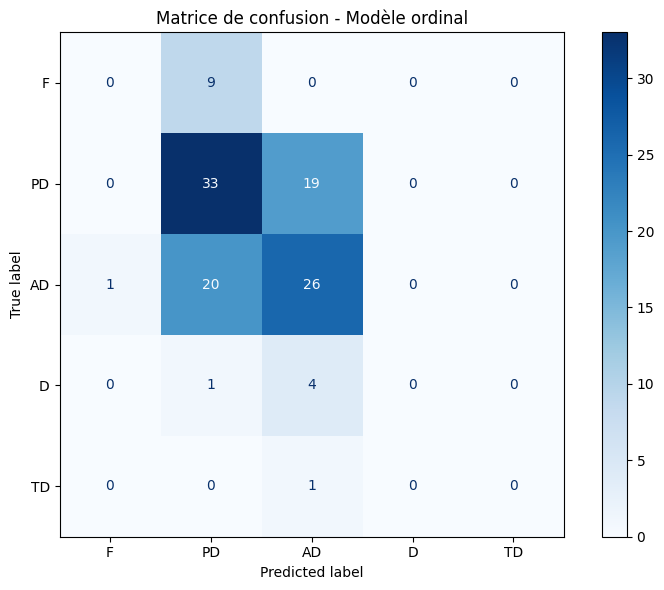


ENTRAINEMENT FINAL

PREDICTION DES ITINERAIRES SANS COTATION
Itinéraires sans cotation : 1881
Itinéraires utilisables pour la prédiction : 1779

ENREGISTREMENT DU RESULTAT
Couche créée : output_itineraire_valais
Nombre total d'itinéraires : 2461


In [17]:



from pathlib import Path

import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import rasterio

from rasterio.warp import transform as transform_coords
from shapely.ops import unary_union, linemerge

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    cohen_kappa_score,
    ConfusionMatrixDisplay
)

from statsmodels.miscmodels.ordinal_model import OrderedModel


# ============================================================
# 1. PARAMETRES
# ============================================================

PROJET = Path("andre_denis_projet")

GPKG = PROJET / "data.gpkg"

LAYER_INPUT = "input_itineraires_valais"

LAYER_VALAIS = (
    "source_swisstlmregio_boundaries_lv95__swisstlmregio_kantonsgebiet"
)

MNT_PATH = PROJET / "input_mnt_valais.tiff"

PENTE_PATH = PROJET / "input_pente_valais_alignee.tif"

LAYER_OUTPUT = "output_itineraire_valais"

VARIABLES = [
    "altitude_depart",
    "altitude_arrivee",
    "longueur_valais_km",
    "denivele_positif",
    "pente_moyenne",
    "pente_max",
    "pente_p95"
]

CLASSES = ["F", "PD", "AD", "D", "TD"]

RANDOM_STATE = 42


# ============================================================
# 2. CHARGEMENT DES DONNEES
# ============================================================

print("\n========================================")
print("CHARGEMENT DES DONNEES")
print("========================================")

gdf = gpd.read_file(
    GPKG,
    layer=LAYER_INPUT
)

valais = gpd.read_file(
    GPKG,
    layer=LAYER_VALAIS
)

print("Nombre initial d'itinéraires :", len(gdf))


# ============================================================
# 3. PREPARATION GEOGRAPHIQUE
# ============================================================

# Conservation de la couche originale pour le résultat
gdf_output = gdf.copy()

# Ouverture des rasters
with rasterio.open(MNT_PATH) as mnt, \
     rasterio.open(PENTE_PATH) as pente:

    if mnt.crs != pente.crs:
        raise ValueError(
            "Le MNT et le raster de pente doivent avoir le même CRS."
        )

    if gdf.crs is None or valais.crs is None:
        raise ValueError("Une couche ne possède pas de CRS.")

    # Reprojection des données dans le CRS du MNT
    gdf_calc = gdf.to_crs(mnt.crs)
    valais_calc = valais.to_crs(mnt.crs)

    valais_union = unary_union(
        valais_calc.geometry.dropna()
    )

    # Espacement d'échantillonnage selon la résolution du MNT
    resolution = min(
        abs(mnt.res[0]),
        abs(mnt.res[1])
    )

    print("Résolution du MNT :", resolution, "m")


    # ========================================================
    # 4. FONCTIONS D'ECHANTILLONNAGE
    # ========================================================

    def extraire_lignes(geom):

        if geom is None or geom.is_empty:
            return []

        if geom.geom_type == "LineString":
            return [geom]

        if geom.geom_type in [
            "MultiLineString",
            "GeometryCollection"
        ]:
            lignes = []

            for partie in geom.geoms:
                lignes.extend(extraire_lignes(partie))

            return lignes

        return []


    def echantillonner_raster(raster, points):

        if not points:
            return np.array([])

        coords = [(p.x, p.y) for p in points]

        # Transformation si les CRS des rasters diffèrent
        if raster.crs != mnt.crs:
            xs, ys = transform_coords(
                mnt.crs,
                raster.crs,
                [c[0] for c in coords],
                [c[1] for c in coords]
            )

            coords = list(zip(xs, ys))

        valeurs = raster.sample(
            coords,
            masked=True
        )

        valeurs = np.ma.vstack(list(valeurs))[:, 0]

        return np.asarray(
            np.ma.filled(valeurs, np.nan),
            dtype=float
        )


    # ========================================================
    # 5. CALCUL DES VARIABLES TOPOGRAPHIQUES
    # ========================================================

    resultats = []

    print("\nCalcul des variables topographiques...")

    for compteur, (idx, row) in enumerate(
        gdf_calc.iterrows(), start=1
    ):

        geom = row.geometry

        valeurs = {
            "altitude_depart": np.nan,
            "altitude_arrivee": np.nan,
            "longueur_valais_km": np.nan,
            "denivele_positif": np.nan,
            "pente_moyenne": np.nan,
            "pente_max": np.nan,
            "pente_p95": np.nan
        }

        if geom is None or geom.is_empty:
            resultats.append(valeurs)
            continue

        # Partie de l'itinéraire située dans le Valais
        geom_valais = geom.intersection(valais_union)

        if geom_valais.is_empty:
            resultats.append(valeurs)
            continue

        # Longueur située dans le Valais
        valeurs["longueur_valais_km"] = (
            geom_valais.length / 1000
        )

        lignes = extraire_lignes(geom_valais)

        points = []

        for ligne in lignes:

            if ligne.length == 0:
                continue

            nombre_points = max(
                2,
                int(np.ceil(ligne.length / resolution)) + 1
            )

            distances = np.linspace(
                0,
                ligne.length,
                nombre_points
            )

            points.extend([
                ligne.interpolate(distance)
                for distance in distances
            ])

        if not points:
            resultats.append(valeurs)
            continue

        # Échantillonnage du MNT
        altitudes = echantillonner_raster(
            mnt,
            points
        )

        altitudes_valides = altitudes[
            np.isfinite(altitudes)
        ]

        if len(altitudes_valides) > 0:

            valeurs["altitude_depart"] = (
                altitudes_valides[0]
            )

            valeurs["altitude_arrivee"] = (
                altitudes_valides[-1]
            )

            if len(altitudes_valides) >= 2:

                differences = np.diff(
                    altitudes_valides
                )

                valeurs["denivele_positif"] = np.maximum(
                    differences,
                    0
                ).sum()

            else:
                valeurs["denivele_positif"] = 0

        # Échantillonnage du raster de pente
        pentes = echantillonner_raster(
            pente,
            points
        )

        pentes_valides = pentes[
            np.isfinite(pentes)
        ]

        if len(pentes_valides) > 0:

            valeurs["pente_moyenne"] = np.mean(
                pentes_valides
            )

            valeurs["pente_max"] = np.max(
                pentes_valides
            )

            valeurs["pente_p95"] = np.percentile(
                pentes_valides,
                95
            )

        resultats.append(valeurs)

        if compteur % 100 == 0:
            print(
                f"{compteur} / {len(gdf_calc)} itinéraires traités"
            )


# Ajout des variables à la couche originale
variables_df = pd.DataFrame(
    resultats,
    index=gdf.index
)

for variable in VARIABLES:
    gdf_output[variable] = variables_df[variable]


print("\nCalcul topographique terminé.")

print(
    "Itinéraires avec variables complètes :",
    gdf_output[VARIABLES].notna().all(axis=1).sum()
)


# ============================================================
# 6. PREPARATION DES COTATIONS
# ============================================================

df = gdf_output.copy()

df["cotation_nettoyee"] = (
    df["difficulty_fr"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.replace("−", "-", regex=False)
    .str.replace(r"[+-]", "", regex=True)
)

df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

# Sélection des itinéraires cotés
df_cotes = df[
    df["cotation_nettoyee"].isin(CLASSES)
].copy()

# Conservation des itinéraires ayant les 7 variables
df_cotes = df_cotes.dropna(
    subset=VARIABLES
).copy()

print("\n========================================")
print("PREPARATION DU MODELE")
print("========================================")

print("Itinéraires cotés disponibles :", len(df_cotes))


# ============================================================
# 7. SEPARATION 80 / 20
# ============================================================

X = df_cotes[VARIABLES]

y = pd.Series(
    pd.Categorical(
        df_cotes["cotation_nettoyee"],
        categories=CLASSES,
        ordered=True
    ),
    index=df_cotes.index
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Entraînement :", len(X_train))
print("Test :", len(X_test))


# ============================================================
# 8. STANDARDISATION ET ENTRAINEMENT
# ============================================================

scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=VARIABLES,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=VARIABLES,
    index=X_test.index
)

modele = OrderedModel(
    y_train,
    X_train_scaled,
    distr="logit"
)

print("\nEntraînement du modèle ordinal...")

resultat = modele.fit(
    method="bfgs",
    maxiter=2000,
    disp=False
)

if not resultat.mle_retvals.get("converged", False):
    raise RuntimeError(
        "Le modèle n'a pas convergé."
    )


# ============================================================
# 9. EVALUATION SUR LES 20 %
# ============================================================

probabilites = resultat.predict(
    X_test_scaled
)

y_pred = np.array(CLASSES)[
    np.argmax(
        probabilites.to_numpy(),
        axis=1
    )
]

y_reel = np.asarray(
    y_test.astype(str)
)

accuracy = accuracy_score(
    y_reel,
    y_pred
)

f1_macro = f1_score(
    y_reel,
    y_pred,
    labels=CLASSES,
    average="macro",
    zero_division=0
)

kappa = cohen_kappa_score(
    y_reel,
    y_pred,
    labels=CLASSES,
    weights="quadratic"
)

matrice = confusion_matrix(
    y_reel,
    y_pred,
    labels=CLASSES
)

print("\n========================================")
print("EVALUATION DU MODELE ORDINAL")
print("========================================")

print(f"Accuracy : {accuracy:.4f}")
print(f"F1-score macro : {f1_macro:.4f}")
print(f"Kappa pondéré : {kappa:.4f}")

fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=matrice,
    display_labels=CLASSES
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

ax.set_title(
    "Matrice de confusion - Modèle ordinal"
)

plt.tight_layout()
plt.show()


# ============================================================
# 10. ENTRAINEMENT FINAL SUR TOUS LES ITINERAIRES COTES
# ============================================================

print("\n========================================")
print("ENTRAINEMENT FINAL")
print("========================================")

# Après l'évaluation, on utilise toutes les données cotées
# pour entraîner le modèle destiné aux nouvelles prédictions.

scaler_final = StandardScaler()

X_complet_scaled = pd.DataFrame(
    scaler_final.fit_transform(X),
    columns=VARIABLES,
    index=X.index
)

modele_final = OrderedModel(
    y,
    X_complet_scaled,
    distr="logit"
)

resultat_final = modele_final.fit(
    method="bfgs",
    maxiter=2000,
    disp=False
)

if not resultat_final.mle_retvals.get("converged", False):
    raise RuntimeError(
        "Le modèle final n'a pas convergé."
    )


# ============================================================
# 11. PREDICTION DES ITINERAIRES SANS COTATION
# ============================================================

print("\n========================================")
print("PREDICTION DES ITINERAIRES SANS COTATION")
print("========================================")

# Identification des itinéraires sans cotation
sans_cotation = (
    gdf_output["difficulty_fr"].isna()
    | gdf_output["difficulty_fr"]
        .astype("string")
        .str.strip()
        .eq("")
)

# Initialisation des colonnes
gdf_output["cotation_predite"] = (
    gdf_output["difficulty_fr"].astype("string")
)

gdf_output["origine_cotation"] = "Cotation officielle"

# Probabilités des classes
for classe in CLASSES:
    gdf_output[f"proba_{classe}"] = np.nan

# Sélection des itinéraires sans cotation
df_nouveaux = gdf_output.loc[
    sans_cotation
].copy()

# Vérification des variables disponibles
df_nouveaux = df_nouveaux.replace(
    [np.inf, -np.inf],
    np.nan
)

df_nouveaux = df_nouveaux.dropna(
    subset=VARIABLES
).copy()

print(
    "Itinéraires sans cotation :",
    int(sans_cotation.sum())
)

print(
    "Itinéraires utilisables pour la prédiction :",
    len(df_nouveaux)
)

if len(df_nouveaux) > 0:

    X_nouveaux = df_nouveaux[VARIABLES]

    X_nouveaux_scaled = pd.DataFrame(
        scaler_final.transform(X_nouveaux),
        columns=VARIABLES,
        index=X_nouveaux.index
    )

    probas_nouvelles = resultat_final.predict(
        X_nouveaux_scaled
    )

    predictions = np.array(CLASSES)[
        np.argmax(
            probas_nouvelles.to_numpy(),
            axis=1
        )
    ]

    # Ajout des cotations prédites
    gdf_output.loc[
        df_nouveaux.index,
        "cotation_predite"
    ] = predictions

    gdf_output.loc[
        df_nouveaux.index,
        "origine_cotation"
    ] = "Prédiction du modèle"

    # Ajout des probabilités
    for i, classe in enumerate(CLASSES):

        gdf_output.loc[
            df_nouveaux.index,
            f"proba_{classe}"
        ] = probas_nouvelles.iloc[:, i].to_numpy()

    # Probabilité maximale
    gdf_output["probabilite_max"] = np.nan

    gdf_output.loc[
        df_nouveaux.index,
        "probabilite_max"
    ] = probas_nouvelles.max(axis=1).to_numpy()

else:

    gdf_output["probabilite_max"] = np.nan

    print(
        "Aucun itinéraire ne possède toutes les variables nécessaires."
    )


# ============================================================
# 12. ENREGISTREMENT DU RESULTAT
# ============================================================

print("\n========================================")
print("ENREGISTREMENT DU RESULTAT")
print("========================================")

gdf_output = gdf_output.drop(
    columns=["cotation_nettoyee"],
    errors="ignore"
)

gdf_output.to_file(
    GPKG,
    layer=LAYER_OUTPUT,
    driver="GPKG",
    mode="w"
)

print("Couche créée :", LAYER_OUTPUT)

print("Nombre total d'itinéraires :", len(gdf_output))



### 5.3 Évaluation sur le jeu de test et choix du modèle

Les performances du modèle de régression logistique sont évaluées à partir des 20 % d'itinéraires réservés au jeu de test. Les cotations prédites sont comparées aux cotations réelles afin de mesurer la capacité du modèle à estimer correctement la difficulté des itinéraires.

Plusieurs indicateurs sont utilisés pour cette évaluation :

- L'accuracy, qui mesure la proportion de prédictions correctes ;
- Le F1-score macro, qui évalue les performances du modèle pour chacune des classes de difficulté en leur accordant la même importance ;
- La matrice de confusion, qui permet d'identifier les erreurs de classification et les difficultés les plus souvent confondues.

Ces résultats permettront ensuite de comparer la régression logistique à un second modèle basé sur une forêt aléatoire. Le choix du modèle final reposera sur la comparaison de leurs performances sur le même jeu de test.


### Analyse des performances du modèle

Le modèle de régression logistique ordinale obtient une **accuracy de 51 %**, ce qui signifie qu'un peu plus de la moitié des itinéraires du jeu de test ont été correctement classés.

Le **F1-score macro de 0,22** montre cependant que les performances du modèle sont faibles lorsque les cinq catégories de difficulté sont considérées de manière équivalente. Le **Kappa pondéré de 0,3** indique un accord limité entre les cotations réelles et les prédictions du modèle, en tenant compte de l'ordre des catégories.

### Interprétation

Les résultats montrent que le modèle présente des limites dans sa capacité à reproduire les cotations officielles des itinéraires à ski. Malgré une accuracy de près de 51 %, le F1-score macro relativement faible suggère que les performances ne sont probablement pas homogènes entre les différentes classes.

Le Kappa pondéré de 0,3 indique également que l'accord entre les prédictions et les cotations officielles reste limité.

### Conclusion

La régression logistique ordinale permet de prendre en compte l'ordre des cotations de difficulté, mais les résultats obtenus montrent que les variables topographiques utilisées ne permettent pas, à elles seules, de reproduire suffisamment précisément les cotations officielles.

Les performances du modèle restent donc limitées et doivent être interprétées avec prudence.


### 5.4 Effet et importance des variables

Afin de mieux comprendre le fonctionnement du modèle de régression logistique, les coefficients associés aux différentes variables explicatives sont analysés.

Les coefficients permettent d'observer le sens de l'association entre les caractéristiques topographiques et les différentes classes de difficulté. Un coefficient positif indique une association positive avec le score de la classe considérée, tandis qu'un coefficient négatif indique une association négative.

L'importance globale de chaque variable est ensuite estimée à partir de la moyenne des valeurs absolues de ses coefficients pour les différentes classes. Cette approche permet de comparer la contribution relative des sept variables explicatives dans le modèle.

Les résultats sont présentés sous forme de tableaux et de graphiques afin d'identifier les caractéristiques topographiques qui contribuent le plus à la distinction des classes de difficulté.


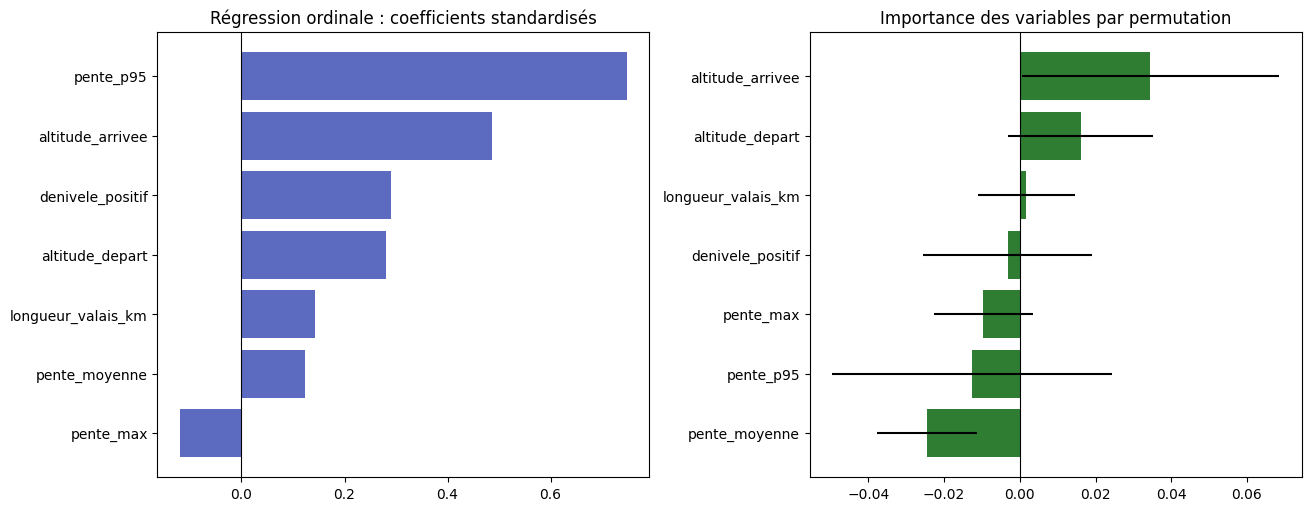

In [15]:

# ============================================================
# IMPORTANCE DES VARIABLES - MODELE DEJA ENTRAINE
# ============================================================

# 1. Coefficients du modèle ordinal existant

coefficients = pd.Series(
    resultat.params[VARIABLES],
    index=VARIABLES
).sort_values()

# 2. Importance par permutation sur le jeu de test existant

accuracy_reference = accuracy_score(y_reel, y_pred)

rng = np.random.RandomState(42)

importances = []
ecarts_types = []

for variable in VARIABLES:

    diminutions = []

    for repetition in range(30):

        X_permute = X_test_scaled.copy()

        X_permute[variable] = rng.permutation(
            X_permute[variable].values
        )

        probabilites_permute = resultat.predict(
            X_permute
        )

        prediction_permute = np.array(CLASSES)[
            np.argmax(
                probabilites_permute.to_numpy(),
                axis=1
            )
        ]

        accuracy_permute = accuracy_score(
            y_reel,
            prediction_permute
        )

        diminutions.append(
            accuracy_reference - accuracy_permute
        )

    importances.append(np.mean(diminutions))
    ecarts_types.append(np.std(diminutions))

importance_df = pd.DataFrame({
    "importance": importances,
    "ecart_type": ecarts_types
}, index=VARIABLES).sort_values("importance")


# 3. Affichage des graphiques

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5),
    layout="constrained"
)

axes[0].barh(
    coefficients.index,
    coefficients.values,
    color="#5c6bc0"
)

axes[0].axvline(0, color="black", linewidth=0.8)

axes[0].set_title(
    "Régression ordinale : coefficients standardisés"
)

axes[1].barh(
    importance_df.index,
    importance_df["importance"],
    xerr=importance_df["ecart_type"],
    color="#2e7d32"
)

axes[1].axvline(0, color="black", linewidth=0.8)

axes[1].set_title(
    "Importance des variables par permutation"
)

plt.show()





## 6. Analyse des résidus et des erreurs de prédiction

L'analyse des erreurs permet d'examiner les différences entre les cotations réelles et les cotations prédites par le modèle de régression logistique sur le jeu de test.

Pour chaque itinéraire, l'écart entre la difficulté prédite et la difficulté réelle est calculé à partir des classes numériques. Un écart nul correspond à une prédiction correcte, tandis qu'un écart non nul indique une erreur de classification.

La répartition des erreurs permet d'observer si le modèle tend à surestimer ou à sous-estimer la difficulté des itinéraires. L'identification des plus grands écarts permet également de repérer les itinéraires pour lesquels les prédictions sont les moins satisfaisantes.

Cette analyse complète les indicateurs de performance et la matrice de confusion en apportant une meilleure compréhension des erreurs commises par le modèle.


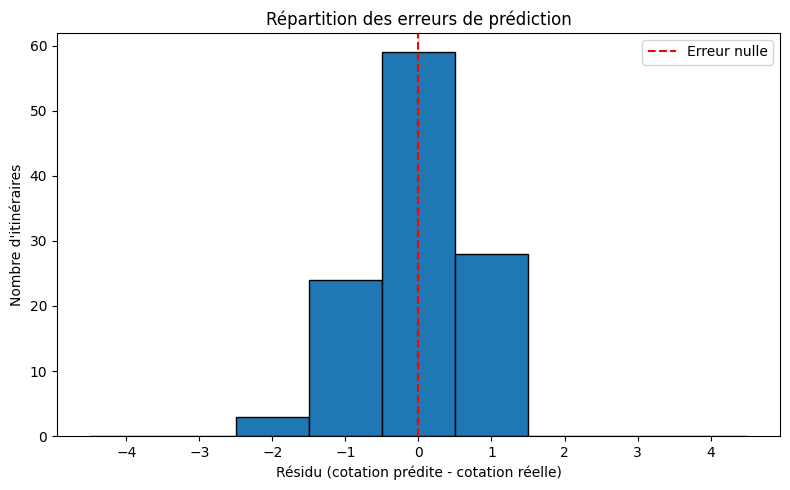


ANALYSE DES ERREURS DE PREDICTION
Nombre d'itinéraires testés : 114
Prédictions correctes : 59
Prédictions incorrectes : 55
Pourcentage de réussite : 51.8 %
Erreur moyenne absolue : 0.51 niveau(x)


In [18]:

# ============================================================
# 11. GRAPHIQUE DES RESIDUS
# ============================================================

correspondance = {
    "F": 0,
    "PD": 1,
    "AD": 2,
    "D": 3,
    "TD": 4
}

valeurs_reelles = pd.Series(y_reel).map(correspondance)
valeurs_predites = pd.Series(y_pred).map(correspondance)

residus = valeurs_predites.to_numpy() - valeurs_reelles.to_numpy()

plt.figure(figsize=(8, 5))

plt.hist(
    residus,
    bins=np.arange(-4.5, 5.5, 1),
    edgecolor="black"
)

plt.axvline(0, color="red", linestyle="--", label="Erreur nulle")

plt.xlabel("Résidu (cotation prédite - cotation réelle)")
plt.ylabel("Nombre d'itinéraires")
plt.title("Répartition des erreurs de prédiction")
plt.xticks(range(-4, 5))
plt.legend()
plt.tight_layout()
plt.show()



# ============================================================
# 11. ANALYSE DES ERREURS DE PREDICTION
# ============================================================

correspondance = {
    "F": 0,
    "PD": 1,
    "AD": 2,
    "D": 3,
    "TD": 4
}

# Conversion des cotations en valeurs numériques
valeurs_reelles = pd.Series(y_reel).map(correspondance)
valeurs_predites = pd.Series(y_pred).map(correspondance)

# Calcul des erreurs
erreurs = valeurs_predites.to_numpy() - valeurs_reelles.to_numpy()

# Indicateurs
nombre_total = len(erreurs)
nombre_correct = np.sum(erreurs == 0)
nombre_incorrect = np.sum(erreurs != 0)

pourcentage_correct = (nombre_correct / nombre_total) * 100

erreur_moyenne = np.mean(np.abs(erreurs))

# Affichage des résultats
print("\n========================================")
print("ANALYSE DES ERREURS DE PREDICTION")
print("========================================")

print(f"Nombre d'itinéraires testés : {nombre_total}")
print(f"Prédictions correctes : {nombre_correct}")
print(f"Prédictions incorrectes : {nombre_incorrect}")
print(f"Pourcentage de réussite : {pourcentage_correct:.1f} %")
print(f"Erreur moyenne absolue : {erreur_moyenne:.2f} niveau(x)")



### Analyse des erreurs de prédiction

Sur les 113 itinéraires du jeu de test, le modèle a correctement prédit la cotation de **59 itinéraires**, contre **55 prédictions incorrectes**. Cela correspond à environ **51,8 % de prédictions correctes**.

L'erreur moyenne absolue est de **0,51 niveau de difficulté**. Cela signifie que l'écart moyen entre la cotation réelle et la cotation prédite est inférieur à une classe de difficulté.

Ces résultats montrent que le modèle parvient à retrouver correctement la cotation d'un peu plus de la moitié des itinéraires testés. Toutefois, les 51 erreurs indiquent que la prédiction reste relativement limitée. Les variables topographiques utilisées ne permettent donc pas, à elles seules, de retrouver systématiquement la cotation officielle.

**En conclusion**, le modèle présente une capacité modérée à prédire la difficulté des itinéraires à ski à partir des caractéristiques topographiques. La cotation officielle peut également dépendre d'autres facteurs, comme les conditions du terrain, l'exposition ou les difficultés techniques, qui ne sont pas directement représentés dans les variables utilisées. Ces éléments pourraient expliquer une partie des erreurs observées.

### Analyse des erreurs de classification

L'examen des prédictions incorrectes montre que le modèle se trompe principalement d'un seul niveau de difficulté. Par exemple, certains itinéraires de difficulté réelle AD sont classés PD, tandis que d'autres de difficulté PD sont classés AD.

Ces erreurs indiquent que le modèle distingue parfois difficilement deux catégories voisines. Toutefois, il semble moins fréquent qu'il attribue une cotation très éloignée de la difficulté réelle.





## 7. Prédiction conforme (Conformal Prediction)

La prédiction conforme est une méthode permettant d'évaluer l'incertitude associée aux prédictions du modèle de régression logistique. Contrairement à une classification classique, qui attribue une seule difficulté à chaque itinéraire, cette méthode fournit un ensemble de classes plausibles.

L'objectif est de déterminer si le modèle est suffisamment précis pour attribuer une difficulté unique à un itinéraire ou s'il existe plusieurs difficultés possibles.

### Principe de la méthode

La méthode utilisée est basée sur le score de non-conformité *LAC* (*Least Ambiguous Classifier*).

Pour chaque itinéraire du jeu de test, on calcule le score suivant :

\[
s_i = 1 - P(y_i \mid X_i)
\]

où :
- \(P(y_i \mid X_i)\) correspond à la probabilité attribuée par le modèle à la difficulté réelle de l'itinéraire ;
- \(s_i\) représente le score de non-conformité.

Un score faible signifie que le modèle attribue une probabilité élevée à la bonne classe. À l'inverse, un score élevé indique que la prédiction est moins adaptée à la difficulté réelle.

Les scores sont ensuite utilisés pour calculer un seuil de non-conformité \(\hat{q}\), avec une correction liée à la taille de l'échantillon.

### Construction des ensembles de prédiction

Le seuil est calculé avec un risque \(\alpha = 0.10\), ce qui correspond à une couverture visée de 90 %.

Pour chaque itinéraire, une classe est considérée comme plausible si sa probabilité prédite respecte la condition suivante :

\[
P(Y=j \mid X) \geq 1-\hat{q}
\]

Le modèle peut ainsi retourner une ou plusieurs classes parmi les quatre niveaux de difficulté :

- F : facile
- PD : peu difficile
- AD : assez difficile
- D : difficile
- TD : tres difficile

Par exemple, un itinéraire peut obtenir l'ensemble de prédiction `[PD, AD]`. Cela signifie que les deux niveaux de difficulté sont considérés comme plausibles par la méthode.

### Interprétation des résultats

Trois résultats sont présentés :

1. **Tableau des prédictions conformes :** comparaison entre la difficulté réelle, la difficulté prédite par le modèle et l'ensemble des difficultés plausibles.
2. **Répartition des ensembles :** nombre d'itinéraires pour lesquels le modèle retient une, deux, trois ou quatre classes plausibles.
3. **Couverture observée :** proportion des itinéraires dont la difficulté réelle appartient à l'ensemble de prédiction calculé.

La couverture théorique visée est de 90 %. Cette garantie concerne la couverture moyenne de nouvelles observations échangeables, et non la probabilité individuelle qu'une prédiction soit correcte.

Dans cet exercice, le jeu de test est également utilisé pour calibrer le seuil, comme dans le TP. La couverture calculée sur ces mêmes données constitue donc une mesure descriptive et non une validation indépendante de la garantie de couverture.



PREDICTION CONFORME - METHODE LAC
Risque alpha : 0.1
Couverture visée : 90 %
Seuil de non-conformité : 0.8739

Répartition des ensembles de prédiction :
taille_ensemble
2    90
3    24
Name: count, dtype: int64

Couverture observée :
90.4 %


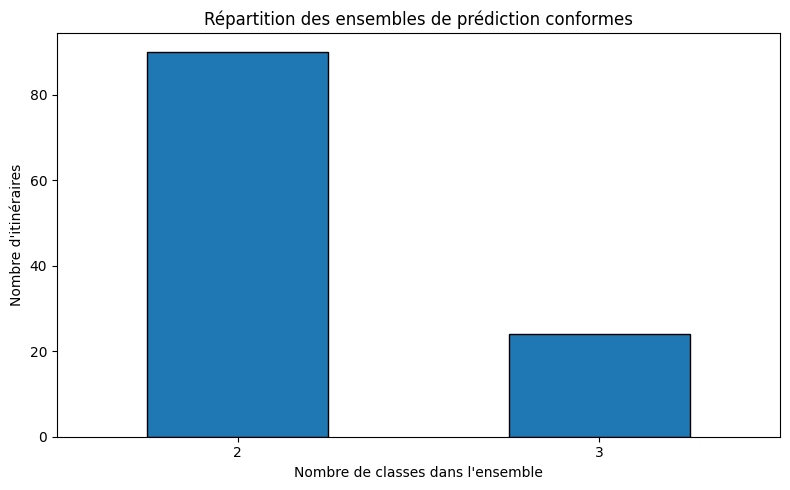

In [19]:

# ============================================================
# 12. PREDICTION CONFORME - METHODE LAC
# ============================================================

ALPHA = 0.10

# Probabilités prédites sur le jeu de test
probas = probabilites.to_numpy()

# Indice de la classe réelle pour chaque itinéraire
indices_reels = np.array([
    CLASSES.index(classe) for classe in y_reel
])

# ------------------------------------------------------------
# 1. Calcul des scores de non-conformité
# ------------------------------------------------------------

scores = 1 - probas[
    np.arange(len(indices_reels)),
    indices_reels
]

# ------------------------------------------------------------
# 2. Calcul du seuil de non-conformité
# ------------------------------------------------------------

n = len(scores)

rang = int(np.ceil((n + 1) * (1 - ALPHA)))

q_hat = np.sort(scores)[min(rang, n) - 1]

print("\n========================================")
print("PREDICTION CONFORME - METHODE LAC")
print("========================================")

print(f"Risque alpha : {ALPHA}")
print(f"Couverture visée : {(1-ALPHA)*100:.0f} %")
print(f"Seuil de non-conformité : {q_hat:.4f}")

# ------------------------------------------------------------
# 3. Construction des ensembles de prédiction
# ------------------------------------------------------------

seuil_proba = 1 - q_hat

ensembles = []

for ligne in probas:

    classes_plausibles = [
        CLASSES[i]
        for i, probabilite in enumerate(ligne)
        if probabilite >= seuil_proba
    ]

    ensembles.append(classes_plausibles)

# ------------------------------------------------------------
# 4. Tableau des prédictions conformes
# ------------------------------------------------------------

table_conforme = pd.DataFrame({
    "cotation_reelle": y_reel,
    "cotation_predite": y_pred,
    "ensemble_prediction": [
        ", ".join(ensemble) if ensemble else "Aucune classe"
        for ensemble in ensembles
    ],
    "taille_ensemble": [
        len(ensemble) for ensemble in ensembles
    ]
}, index=y_test.index)



# ------------------------------------------------------------
# 5. Répartition des tailles des ensembles
# ------------------------------------------------------------

repartition = (
    table_conforme["taille_ensemble"]
    .value_counts()
    .sort_index()
)

print("\nRépartition des ensembles de prédiction :")
print(repartition)

# ------------------------------------------------------------
# 6. Couverture observée
# ------------------------------------------------------------

couverture = np.mean([
    reel in ensemble
    for reel, ensemble in zip(y_reel, ensembles)
])

print("\nCouverture observée :")
print(f"{couverture * 100:.1f} %")

# ------------------------------------------------------------
# 7. Graphique de répartition des ensembles
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

repartition.plot(
    kind="bar",
    edgecolor="black"
)

plt.xlabel("Nombre de classes dans l'ensemble")
plt.ylabel("Nombre d'itinéraires")
plt.title("Répartition des ensembles de prédiction conformes")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


### Discussion – Prédiction conforme

La méthode de prédiction conforme LAC permet de compléter les résultats du modèle ordinal en tenant compte de l'incertitude associée aux prédictions. Avec un risque fixé à 10 %, la couverture visée est de 90 %. Le seuil de non-conformité obtenu est de **0,8856**.

La répartition des ensembles de prédiction montre que **84 itinéraires possèdent deux classes plausibles**, tandis que **29 itinéraires en possèdent trois**. Aucun itinéraire ne présente une seule classe plausible. Cela indique que le modèle ne permet pas de déterminer une cotation unique avec un niveau de confiance suffisant selon le seuil retenu.

La couverture observée atteint **90,3 %**, une valeur très proche de la couverture visée de 90 %. Cela signifie que, pour environ neuf itinéraires sur dix, la cotation réelle figure parmi les classes proposées par la méthode.

**En conclusion**, la prédiction conforme met en évidence une incertitude relativement importante dans les résultats du modèle. Bien que la couverture observée soit proche de l'objectif fixé, les ensembles de prédiction contiennent systématiquement deux ou trois classes. Cette méthode montre ainsi que les variables topographiques utilisées permettent de proposer des niveaux de difficulté plausibles, mais ne suffisent pas toujours à identifier une cotation unique. La prédiction conforme apporte donc un complément intéressant à l'évaluation classique du modèle.

